In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Data

In [2]:
df=pd.read_csv("Dataset/bank-additional-full.csv", sep=";")
print(df)

       age          job  marital            education  default housing loan  \
0       56    housemaid  married             basic.4y       no      no   no   
1       57     services  married          high.school  unknown      no   no   
2       37     services  married          high.school       no     yes   no   
3       40       admin.  married             basic.6y       no      no   no   
4       56     services  married          high.school       no      no  yes   
...    ...          ...      ...                  ...      ...     ...  ...   
41183   73      retired  married  professional.course       no     yes   no   
41184   46  blue-collar  married  professional.course       no      no   no   
41185   56      retired  married    university.degree       no     yes   no   
41186   44   technician  married  professional.course       no      no   no   
41187   74      retired  married  professional.course       no     yes   no   

         contact month day_of_week  ...  campaign  

## Data Inspection

In [3]:
print(df.shape)

(41188, 21)


In [4]:
print(df.head())

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [5]:
print(df.tail())

       age          job  marital            education default housing loan  \
41183   73      retired  married  professional.course      no     yes   no   
41184   46  blue-collar  married  professional.course      no      no   no   
41185   56      retired  married    university.degree      no     yes   no   
41186   44   technician  married  professional.course      no      no   no   
41187   74      retired  married  professional.course      no     yes   no   

        contact month day_of_week  ...  campaign  pdays  previous  \
41183  cellular   nov         fri  ...         1    999         0   
41184  cellular   nov         fri  ...         1    999         0   
41185  cellular   nov         fri  ...         2    999         0   
41186  cellular   nov         fri  ...         1    999         0   
41187  cellular   nov         fri  ...         3    999         1   

          poutcome emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  \
41183  nonexistent         -1.1        

In [6]:
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [7]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [8]:
print(df.describe())

               age      duration      campaign         pdays      previous  \
count  41188.00000  41188.000000  41188.000000  41188.000000  41188.000000   
mean      40.02406    258.285010      2.567593    962.475454      0.172963   
std       10.42125    259.279249      2.770014    186.910907      0.494901   
min       17.00000      0.000000      1.000000      0.000000      0.000000   
25%       32.00000    102.000000      1.000000    999.000000      0.000000   
50%       38.00000    180.000000      2.000000    999.000000      0.000000   
75%       47.00000    319.000000      3.000000    999.000000      0.000000   
max       98.00000   4918.000000     56.000000    999.000000      7.000000   

       emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   nr.employed  
count  41188.000000    41188.000000   41188.000000  41188.000000  41188.000000  
mean       0.081886       93.575664     -40.502600      3.621291   5167.035911  
std        1.570960        0.578840       4.628198    

In [9]:
print(df["pdays"].value_counts().sort_index())

pdays
0         15
1         26
2         61
3        439
4        118
5         46
6        412
7         60
8         18
9         64
10        52
11        28
12        58
13        36
14        20
15        24
16        11
17         8
18         7
19         3
20         1
21         2
22         3
25         1
26         1
27         1
999    39673
Name: count, dtype: int64


In [10]:
for col in ["y", "job", "contact", "poutcome"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- y ---
y
no     36548
yes     4640
Name: count, dtype: int64

--- job ---
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

--- contact ---
contact
cellular     26144
telephone    15044
Name: count, dtype: int64

--- poutcome ---
poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64


## Initial Dataset Understanding

- This dataset contains information about a marketing campaign run by a Portuguese bank through phone calls to promote term deposits.
- It has 41,188 records and 21 columns.
- Each row represents a customer's record, and y indicates whether they subscribed to a term deposit.
- Some columns contain unknown, and pdays has the special value 999, meaning the customer was not previously contacted in an earlier campaign.

## Data Cleaning

In [11]:
print(df.isnull().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [12]:
print(df.duplicated().sum())

12


In [13]:
duplicates = df[df.duplicated(keep=False)]
display(duplicates)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [14]:
df=df.drop_duplicates()

In [15]:
df.shape

(41176, 21)

In [16]:
print(df.duplicated().sum())

0


In [17]:
for col in ['job','marital','education','default','housing','loan','contact','month','day_of_week','poutcome','y']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- job ---
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

--- marital ---
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

--- education ---
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

--- default ---
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

--- housing ---
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

--- loan ---
loan
no         33938
yes         6248
unknown      9

In [18]:
unknown_cols = [
    "job", "marital", "education",
    "default", "housing", "loan"
]

for col in unknown_cols:
    count = (df[col] == "unknown").sum()
    percentage = count / len(df) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

job: 330 (0.80%)
marital: 80 (0.19%)
education: 1730 (4.20%)
default: 8596 (20.88%)
housing: 990 (2.40%)
loan: 990 (2.40%)


In [19]:
pd.crosstab(df["previous"], df["poutcome"])

poutcome,failure,nonexistent,success
previous,,,
0,0,35551,0
1,3696,0,865
2,434,0,320
3,88,0,128
4,30,0,40
5,3,0,15
6,1,0,4
7,0,0,1


In [20]:
pd.crosstab(df["pdays"].eq(999), df["previous"].gt(0))

previous,False,True
pdays,,
False,0,1515
True,35551,4110


## Conclusion

- No missing values were found, and 12 duplicate rows were removed.
- Unknown values and pdays = 999 were retained because they represent unavailable information and previous contact history.
- In 4,110 records, pdays = 999 while previous > 0. These values were retained without modification for further analysis.

## EDA

In [22]:
df['y'].value_counts()

y
no     36537
yes     4639
Name: count, dtype: int64

In [38]:
print(df['y'].value_counts(normalize=True)*100)

y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


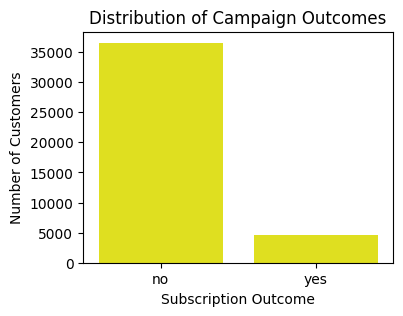

In [40]:
plt.figure(figsize=(4, 3))
sns.barplot(
    x=df["y"].value_counts().index,
    y=df["y"].value_counts().values,
    color='yellow'
)
plt.title("Distribution of Campaign Outcomes")
plt.xlabel("Subscription Outcome")
plt.ylabel("Number of Customers")
plt.show()

In [41]:
pd.crosstab(df["job"], df["y"])

y,no,yes
job,,
admin.,9068,1351
blue-collar,8615,638
entrepreneur,1332,124
housemaid,954,106
management,2596,328
retired,1284,434
self-employed,1272,149
services,3644,323
student,600,275


In [42]:
pd.crosstab(df["job"], df["y"], normalize="index") * 100

y,no,yes
job,,
admin.,87.033305,12.966695
blue-collar,93.104939,6.895061
entrepreneur,91.483516,8.516484
housemaid,90.000000,10.000000
management,88.782490,11.217510
retired,74.738068,25.261932
self-employed,89.514426,10.485574
services,91.857827,8.142173
student,68.571429,31.428571


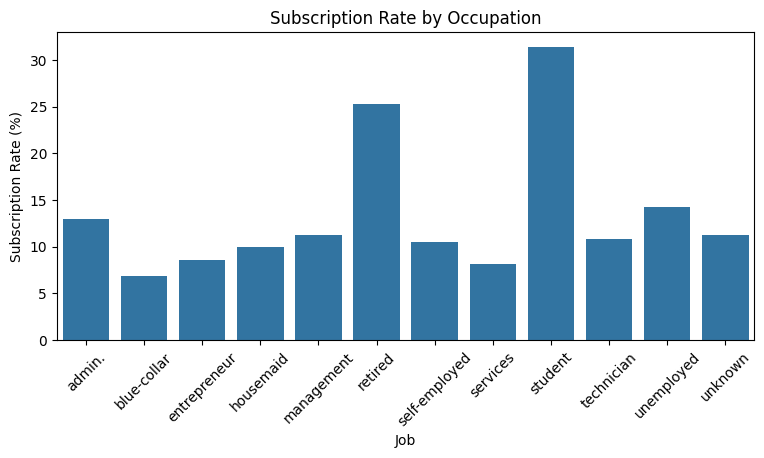

In [47]:
job_rate = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
)["yes"] * 100
plt.figure(figsize=(9, 4))
sns.barplot(x=job_rate.index, y=job_rate.values)
plt.title("Subscription Rate by Occupation")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.show()